In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

In [2]:
TRAIN_DIR = Path("../nfl-big-data-bowl-2026-prediction") / "train"

# Compact dtypes: low-cardinality strings become categories, numerics are downcast.
INPUT_DTYPES = {
    "game_id": "int32",
    "play_id": "int16",
    "player_to_predict": "bool",
    "nfl_id": "int32",
    "frame_id": "int16",
    "play_direction": "category",
    "absolute_yardline_number": "int8",
    "player_name": "category",
    "player_height": "category",
    "player_weight": "int16",
    "player_position": "category",
    "player_side": "category",
    "player_role": "category",
    "x": "float32",
    "y": "float32",
    "s": "float32",
    "a": "float32",
    "dir": "float32",
    "o": "float32",
    "num_frames_output": "int16",
    "ball_land_x": "float32",
    "ball_land_y": "float32",
}
OUTPUT_DTYPES = {
    "game_id": "int32",
    "play_id": "int16",
    "nfl_id": "int32",
    "frame_id": "int16",
    "x": "float32",
    "y": "float32",
}

In [3]:
def load_split(prefix: str, dtypes: dict) -> pd.DataFrame:
    """Load and concatenate all weekly files, e.g. input_2023_w01.csv ... w18."""
    files = sorted(TRAIN_DIR.glob(f"{prefix}_*.csv"))
    if not files:
        raise FileNotFoundError(f"No {prefix}_*.csv files in {TRAIN_DIR}")
    frames = []
    for f in files:
        df = pd.read_csv(f, dtype=dtypes, parse_dates=["player_birth_date"] if prefix == "input" else None)
        df["week"] = int(f.stem.rsplit("_w", 1)[1])
        frames.append(df)
    return pd.concat(frames, ignore_index=True)


In [4]:
inputs = load_split("input", INPUT_DTYPES)
outputs = load_split("output", OUTPUT_DTYPES)

In [5]:
inputs

,game_id,play_id,player_to_predict,nfl_id,frame_id,play_direction,absolute_yardline_number,player_name,player_height,player_weight,...,x,y,s,a,dir,o,num_frames_output,ball_land_x,ball_land_y,week
0,2023090700,101,False,54527,1,right,42,Bryan Cook,6-1,210,...,52.330002,36.939999,0.09,0.39,322.399994,238.240005,21,63.259998,-0.22,1
1,2023090700,101,False,54527,2,right,42,Bryan Cook,6-1,210,...,52.330002,36.939999,0.04,0.61,200.889999,236.050003,21,63.259998,-0.22,1
2,2023090700,101,False,54527,3,right,42,Bryan Cook,6-1,210,...,52.330002,36.930000,0.12,0.73,147.550003,240.600006,21,63.259998,-0.22,1
3,2023090700,101,False,54527,4,right,42,Bryan Cook,6-1,210,...,52.349998,36.919998,0.23,0.81,131.399994,244.250000,21,63.259998,-0.22,1
4,2023090700,101,False,54527,5,right,42,Bryan Cook,6-1,210,...,52.369999,36.900002,0.35,0.82,123.260002,244.250000,21,63.259998,-0.22,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4880574,2024010713,4018,True,52457,23,left,50,Chase Claypool,6-4,227,...,41.610001,17.570000,7.81,0.58,267.160004,296.920013,18,32.139999,6.71,18
4880575,2024010713,4018,True,52457,24,left,50,Chase Claypool,6-4,227,...,40.820000,17.520000,7.92,0.19,266.399994,292.799988,18,32.139999,6.71,18
4880576,2024010713,4018,True,52457,25,left,50,Chase Claypool,6-4,227,...,40.029999,17.459999,7.92,0.69,265.489990,290.540009,18,32.139999,6.71,18
4880577,2024010713,4018,True,52457,26,left,50,Chase Claypool,6-4,227,...,39.240002,17.360001,7.94,1.46,263.260010,287.739990,18,32.139999,6.71,18


In [6]:
#Number of plays per game_id on avergae
inputs.groupby("game_id")["play_id"].nunique().describe()

# number of frames per play
inputs.groupby("play_id")["frame_id"].nunique().describe()


count    4317.000000
mean       35.386843
std        11.064287
min        10.000000
25%        28.000000
50%        34.000000
75%        40.000000
max       123.000000
Name: frame_id, dtype: float64

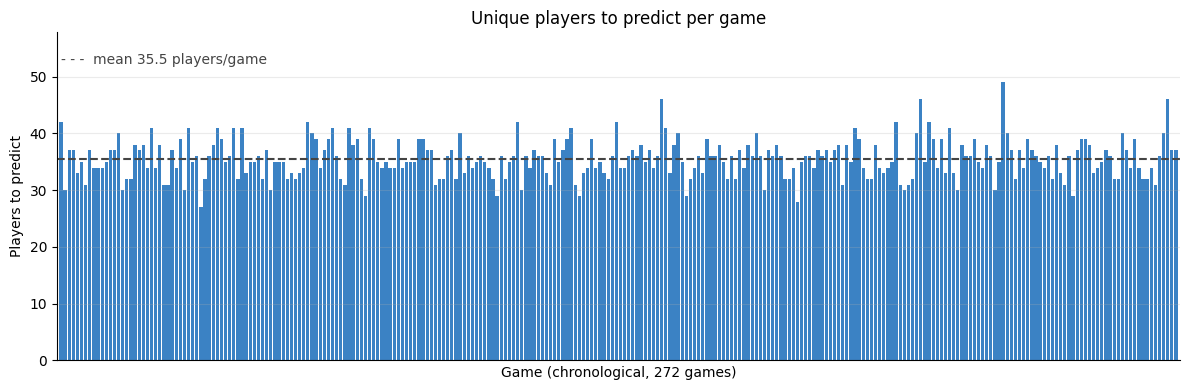

count    272.000000
mean      35.533088
std        3.403765
min       27.000000
25%       33.000000
50%       35.000000
75%       38.000000
max       49.000000
dtype: float64


In [7]:
# Unique players to predict per game
players_per_game = (
    inputs.loc[inputs["player_to_predict"], ["game_id", "nfl_id"]]
    .drop_duplicates()
    .groupby("game_id")
    .size()
    .sort_index()          # game_ids are date-ordered, so this is chronological
)
mean_n = players_per_game.mean()
n_games = len(players_per_game)

fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(range(n_games), players_per_game.values, width=0.8, color="#3b82c4")
ax.axhline(mean_n, color="#444", lw=1.5, ls="--")
ax.set_xlim(-1, n_games)
ax.set_ylim(0, players_per_game.max() * 1.18)
ax.text(0, players_per_game.max() * 1.08, f"- - -  mean {mean_n:.1f} players/game", color="#444", va="center")

ax.set_title("Unique players to predict per game")
ax.set_xlabel(f"Game (chronological, {n_games} games)")
ax.set_ylabel("Players to predict")
ax.set_xticks([])
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

print(players_per_game.describe())

What it shows:

Each game has about 35.5 unique players to predict (median 35).
The range is 27 to 49 across the 272 games.
The spread is tight (standard deviation 3.4), so games look similar in size and there are no extreme outliers.
A game has about 22 players on the field, so 35 means different players come in over the course of a game, not one fixed set.

In [8]:
players_to_predict = inputs[inputs["player_to_predict"]]
players_to_predict[players_to_predict["game_id"] == 2023090700][["game_id", "nfl_id", "play_id"]].groupby("play_id").size()

play_id
101      78
194     160
219      51
361     153
436      60
461     138
530      60
621     116
713      72
736     155
877     170
902     160
1001    190
1069     62
1154    165
1201     57
1300     19
1422    162
1494    150
1563    135
1588    150
1618     66
1679    186
1711    130
1741    100
1812     66
1837     27
1869    112
1940    195
2118    104
2141     99
2186     64
2261     56
2306    104
2364     75
2435     34
2487    176
2510     68
2613    175
2638     80
2825     40
2906     62
2936     54
2959     46
3032     40
3089    116
3114    160
3185    111
3233     30
3324    104
3461    124
3486     34
3566    114
3674     48
3912    190
3971     84
3994    165
4041    469
dtype: int64

<Axes: >

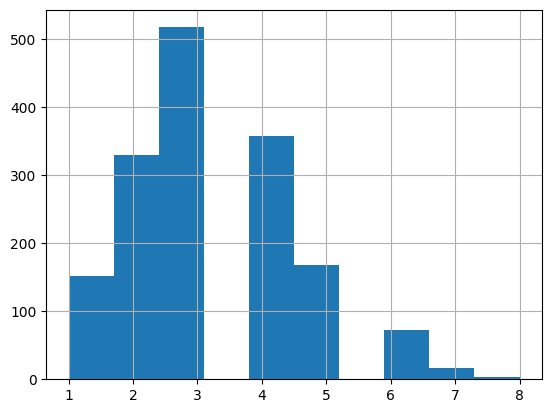

In [9]:
# Take random 500 play_ids
random_plays = players_to_predict["play_id"].drop_duplicates().sample(500, random_state=42)
# chart how many players to predict per play in the random sample
players_to_predict_random = players_to_predict[players_to_predict["play_id"].isin(random_plays)]
players_to_predict_random.drop_duplicates(["play_id", "game_id", "nfl_id"]).groupby(["play_id", "game_id"]).size().hist()

In [10]:
# number of frames per play per game per player
print("Number of frames per play:")
print(players_to_predict.groupby(["game_id", "play_id", "nfl_id"])["frame_id"].nunique().describe())

Number of frames per play:
count    46045.000000
mean        28.307960
std          9.115599
min          8.000000
25%         22.000000
50%         27.000000
75%         33.000000
max        123.000000
Name: frame_id, dtype: float64


In [11]:
# number of frames to predict per play/game/player
print("Number of frames to predict per play per game per player:")
print((inputs.groupby(["game_id", "play_id"])["num_frames_output"].nunique() > 1).sum()) # 0

# Per play
per_play = inputs.drop_duplicates(["game_id", "play_id"])["num_frames_output"]
print("per play:\n", per_play.agg(["mean", "std", "min", "max"]))


Number of frames to predict per play per game per player:
0
per play:
 mean    11.366601
std      5.147501
min      5.000000
max     94.000000
Name: num_frames_output, dtype: float64


In [12]:
#outlier?
inputs[inputs["num_frames_output"] == 94]

,game_id,play_id,player_to_predict,nfl_id,frame_id,play_direction,absolute_yardline_number,player_name,player_height,player_weight,...,x,y,s,a,dir,o,num_frames_output,ball_land_x,ball_land_y,week
283321,2023091100,3167,True,54650,1,left,33,Christian Benford,6-1,205,...,31.440001,38.310001,0.35,0.08,113.320000,41.959999,94,9.72,45.459999,1
283322,2023091100,3167,True,54650,2,left,33,Christian Benford,6-1,205,...,31.450001,38.320000,0.29,0.11,108.900002,41.959999,94,9.72,45.459999,1
283323,2023091100,3167,True,54650,3,left,33,Christian Benford,6-1,205,...,31.469999,38.360001,0.26,0.13,94.480003,44.660000,94,9.72,45.459999,1
283324,2023091100,3167,True,54650,4,left,33,Christian Benford,6-1,205,...,31.490000,38.410000,0.25,0.41,72.099998,45.939999,94,9.72,45.459999,1
283325,2023091100,3167,True,54650,5,left,33,Christian Benford,6-1,205,...,31.510000,38.439999,0.29,1.53,39.619999,49.270000,94,9.72,45.459999,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
283654,2023091100,3167,True,54475,22,left,33,Garrett Wilson,6-0,192,...,25.730000,38.700001,7.06,2.10,301.640015,6.080000,94,9.72,45.459999,1
283655,2023091100,3167,True,54475,23,left,33,Garrett Wilson,6-0,192,...,25.139999,39.099998,7.14,2.65,305.200012,357.190002,94,9.72,45.459999,1
283656,2023091100,3167,True,54475,24,left,33,Garrett Wilson,6-0,192,...,24.580000,39.540001,7.15,3.05,308.799988,7.010000,94,9.72,45.459999,1
283657,2023091100,3167,True,54475,25,left,33,Garrett Wilson,6-0,192,...,24.030001,40.000000,7.13,2.95,311.450012,14.840000,94,9.72,45.459999,1


In [13]:
# position of players to predict
print("Position of players to predict:")
print(players_to_predict["player_position"].value_counts())

# player side to predict
print("Player side to predict:")
print(players_to_predict["player_side"].value_counts())


Position of players to predict:
player_position
CB     371504
WR     238910
FS     149236
SS     121294
ILB    104299
TE      91654
OLB     74113
MLB     73357
RB      62327
DE       6698
S        4883
FB       2460
DT       1246
QB        917
NT        428
T          83
LB         31
Name: count, dtype: int64
Player side to predict:
player_side
Defense    906526
Offense    396914
Name: count, dtype: int64


In [14]:
#player role
print("Player role to predict:")
print(players_to_predict["player_role"].value_counts())

Player role to predict:
player_role
Defensive Coverage    906526
Targeted Receiver     396914
Other Route Runner         0
Passer                     0
Name: count, dtype: int64


In [15]:
# Loading only 1 week of data for exploration
week = 1
inputs_week = inputs[inputs["week"] == week]
outputs_week = outputs[outputs["week"] == week]
players_to_predict_week = players_to_predict[players_to_predict["week"] == week]

In [16]:
inputs_week[inputs_week["play_direction"] == "left"]["x"].describe()

count    133495.000000
mean         59.625076
std          22.266558
min           1.210000
25%          43.459999
50%          61.689999
75%          77.550003
max         112.559998
Name: x, dtype: float64

In [17]:
inputs_week[inputs_week["play_direction"] == "right"]["x"].describe()

count    152219.000000
mean         61.204147
std          25.414312
min           2.780000
25%          40.730000
50%          55.860001
75%          80.370003
max         119.860001
Name: x, dtype: float64

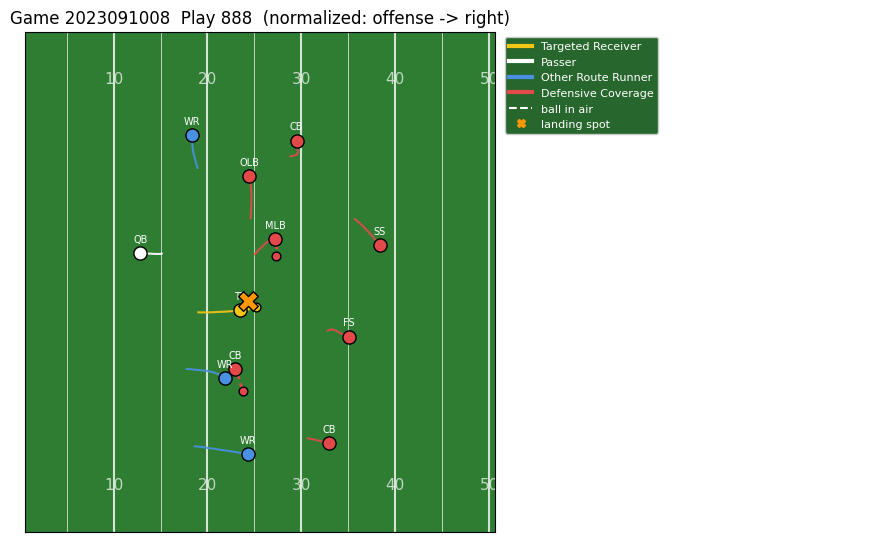

In [18]:
from viz_play import load_week, get_play, plot_play, animate_play
from IPython.display import HTML

# inp, out = load_week("data/train", 1)   # folder with input_2023_w01.csv / output_2023_w01.csv
play = get_play(inputs_week, outputs_week, game_id = 2023091008, play_id=888)               # random play, or pass game_id=..., play_id=...
plot_play(play)
HTML(animate_play(play).to_jshtml())

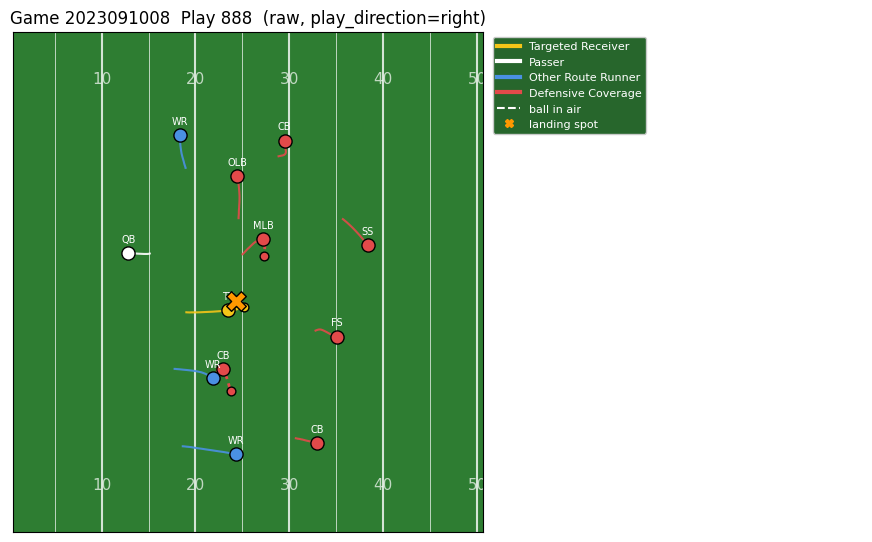

In [19]:
play = get_play(inputs_week, outputs_week, game_id = 2023091008, play_id=888,normalize_dir = False)               # random play, or pass game_id=..., play_id=...
plot_play(play)
HTML(animate_play(play).to_jshtml())

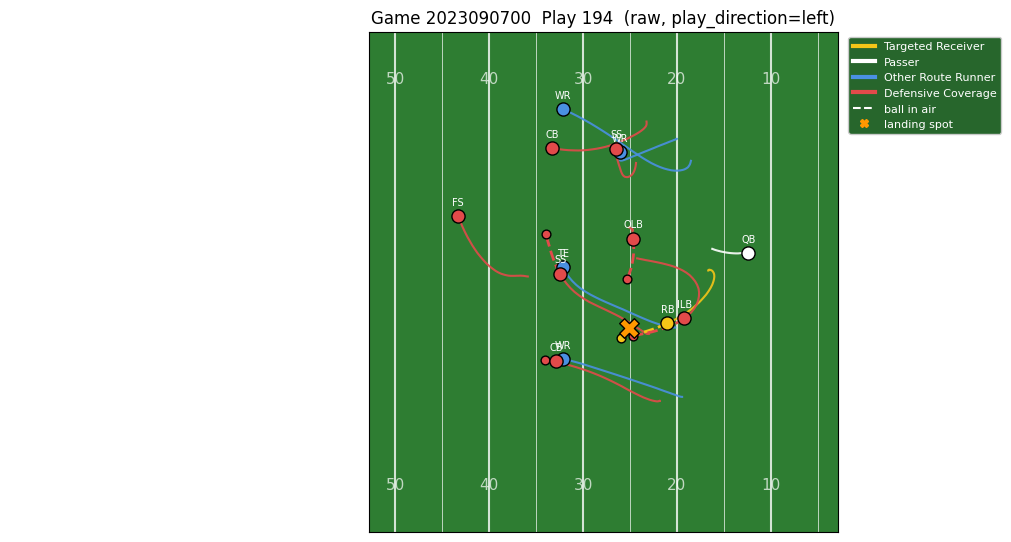

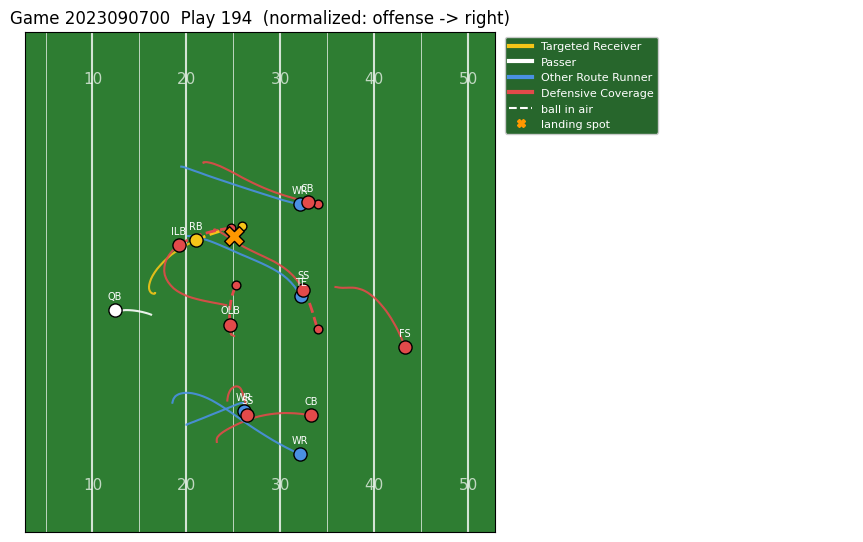

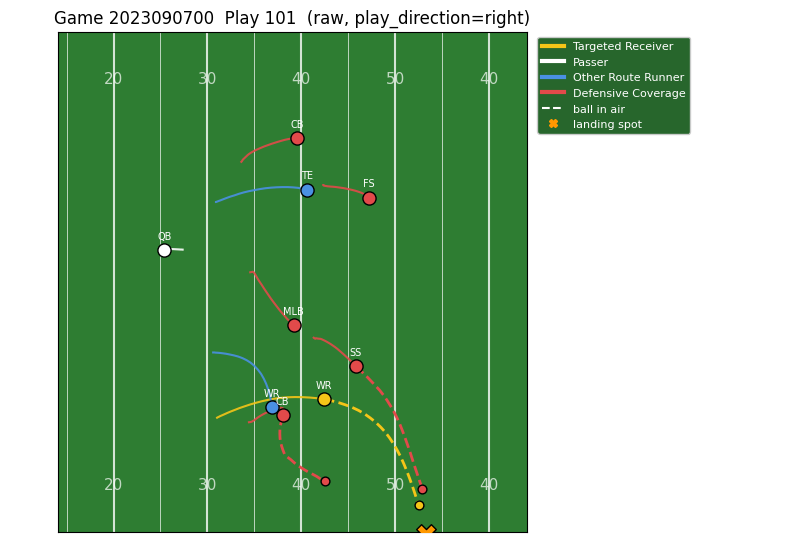

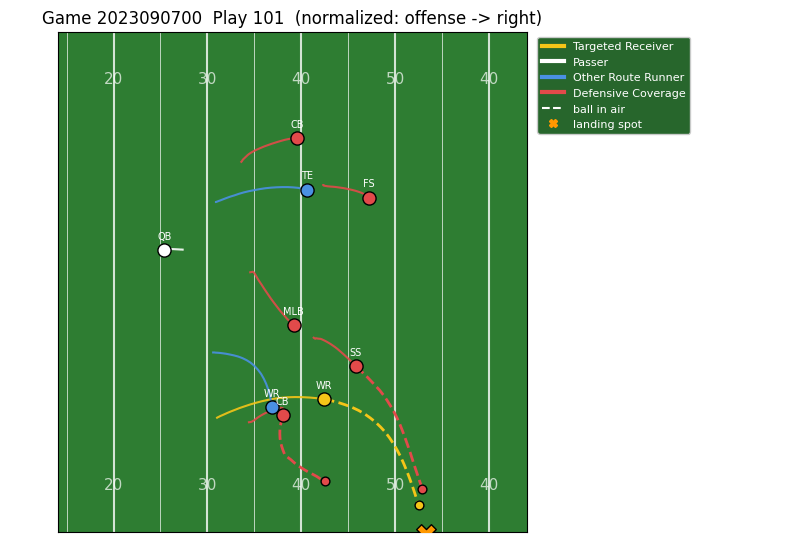

In [20]:
keys = inputs[["game_id", "play_id", "play_direction"]].drop_duplicates()
left  = keys[keys.play_direction == "left"].iloc[0]
right = keys[keys.play_direction == "right"].iloc[0]

for k in (left, right):
    for norm in (False, True):
        p = get_play(inputs_week, outputs_week, k.game_id, k.play_id, normalize_dir=norm)
        plot_play(p)


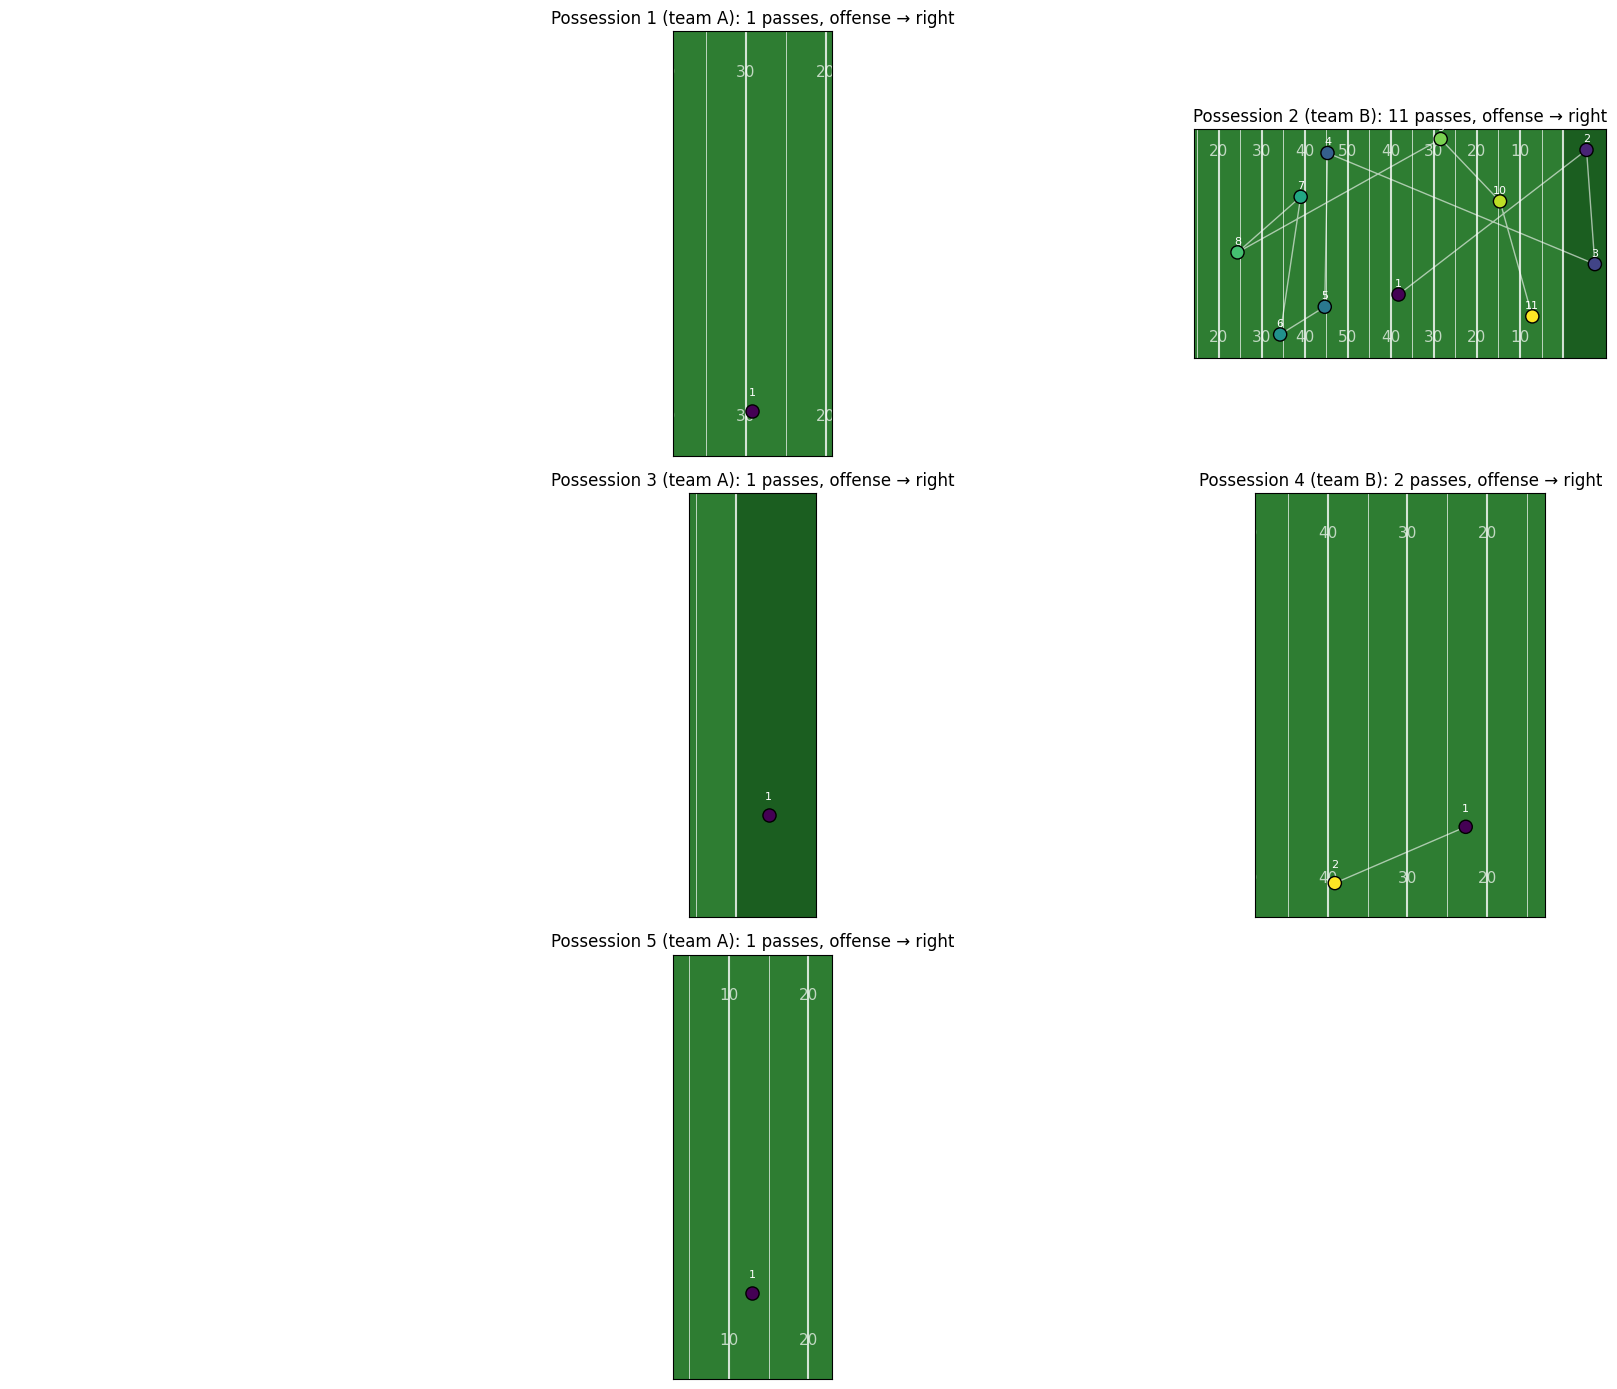

In [40]:
import matplotlib.pyplot as plt
from viz_play import draw_field, normalize

GAME_ID = 2023091008   # change me
N_SEGMENTS = 5         # how many possessions to plot

g = inputs[inputs.game_id == GAME_ID]

# Offensive players on each play, in play order
off = g[g.player_side == "Offense"].groupby("play_id")["nfl_id"].agg(set).sort_index()

# Label each play's offense as team "A" (same players as the first play) or "B"
ref = off.iloc[0]
team = off.apply(lambda s: "A" if len(s & ref) >= 5 else "B")

plays = (
    g.drop_duplicates("play_id")
    [["play_id", "play_direction", "ball_land_x", "ball_land_y"]]
    .sort_values("play_id")
    .reset_index(drop=True)
)
plays["team"] = team.loc[plays.play_id].values
plays["possession"] = (plays.team != plays.team.shift()).cumsum() - 1   # 0, 1, 2, ...

# Rotate left-moving plays so the offense always attacks toward +x
# plays = normalize(plays, has_angles=False)

segments = plays[plays.possession < N_SEGMENTS]

fig, axs = plt.subplots(3, 2, figsize=(14, 14))
axs = axs.ravel()
for ax in axs[N_SEGMENTS:]:
    ax.axis("off")

for k, (pid, seg) in zip(range(N_SEGMENTS), segments.groupby("possession")):
    ax = axs[k]
    draw_field(ax)
    ax.plot(seg.ball_land_x, seg.ball_land_y, color="white", lw=1, alpha=0.6, zorder=2)
    sc = ax.scatter(seg.ball_land_x, seg.ball_land_y, c=range(len(seg)), cmap="viridis",
                    s=90, edgecolor="black", zorder=3)
    for i, (x, y) in enumerate(zip(seg.ball_land_x, seg.ball_land_y), start=1):
        ax.text(x, y + 2, str(i), color="white", fontsize=8, ha="center", zorder=4)
    ax.set_xlim(max(0, seg.ball_land_x.min() - 10), min(120, seg.ball_land_x.max() + 10))
    ax.set_title(f"Possession {pid + 1} (team {seg.team.iloc[0]}): {len(seg)} passes, offense → right")

plt.tight_layout()
plt.show()


In [29]:

# check if direection angle is calculated on x-axis or y-axisx

import numpy as np

df = inputs_week.sort_values(["game_id", "play_id", "nfl_id", "frame_id"])
g = df.groupby(["game_id", "play_id", "nfl_id"])
dx = g["x"].shift(-1) - df["x"]
dy = g["y"].shift(-1) - df["y"]

moving = df["s"] > 2  # direction is noisy when players barely move
compass = np.degrees(np.arctan2(dx, dy)) % 360  # 0° = +y, clockwise
math    = np.degrees(np.arctan2(dy, dx)) % 360  # 0° = +x, counter-clockwise

def ang_err(a, b):
    return np.abs((a - b + 180) % 360 - 180)

print("compass:", ang_err(compass, df["dir"])[moving].median())
print("math:   ", ang_err(math,    df["dir"])[moving].median())

compass: 1.3646622
math:    90.278


# Above test shows the angle is calculated with 0 degrees along y axis

                0
count  100.000000
mean     0.025975
std      0.006755
min      0.011084
25%      0.020733
50%      0.026514
75%      0.030378
max      0.043706


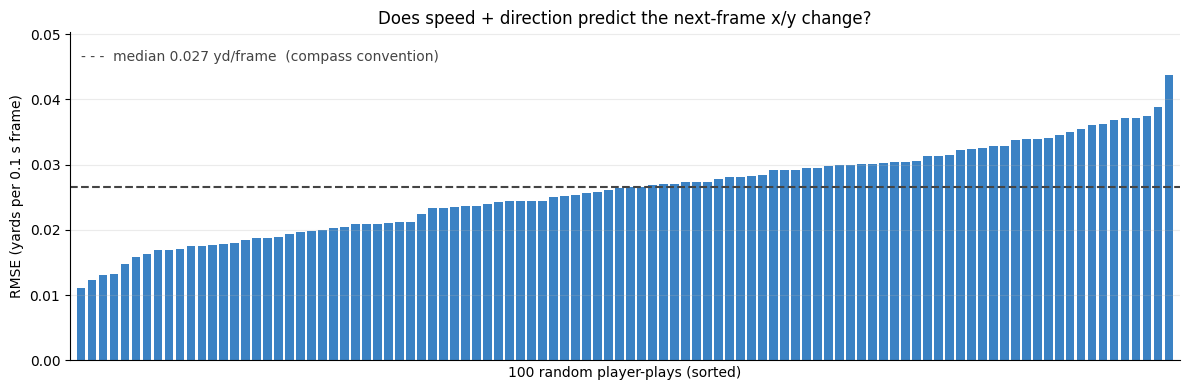

In [37]:
import numpy as np
import matplotlib.pyplot as plt

DT = 0.1                      # frames are 10 Hz; s is in yards/second
KEYS = ["game_id", "play_id", "nfl_id"]

# 100 random player-plays (one player in one play)
sample = inputs[KEYS].drop_duplicates().sample(100, random_state=0)
sub = inputs.merge(sample, on=KEYS)

def rmse_player(d, convention="compass"):
    d = d.sort_values("frame_id")
    dx = d.x.diff().shift(-1)           # actual displacement t -> t+1
    dy = d.y.diff().shift(-1)
    th = np.deg2rad(d["dir"].astype(float))
    # 0° = +y (upfield), clockwise: 90° = +x
    vx, vy = d.s * np.sin(th), d.s * np.cos(th)
    err2 = (dx - vx * DT) ** 2 + (dy - vy * DT) ** 2
    return np.sqrt(err2.mean())         # mean skips the NaN last frame

results = {}
results = pd.Series(
    {k: rmse_player(d, "compass") for k, d in sub.groupby(KEYS)}
)

print(pd.DataFrame(results).describe())   # which convention fits better?

r = results.sort_values()

fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(range(len(r)), r.values, width=0.8, color="#3b82c4")
ax.axhline(r.median(), color="#444", ls="--", lw=1.5)
ax.text(0, r.max() * 1.05, f"- - -  median {r.median():.3f} yd/frame  (compass convention)", color="#444")
ax.set_ylim(0, r.max() * 1.15)
ax.set_xlim(-1, len(r))
ax.set_xticks([])
ax.set_xlabel("100 random player-plays (sorted)")
ax.set_ylabel("RMSE (yards per 0.1 s frame)")
ax.set_title("Does speed + direction predict the next-frame x/y change?")
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()


# Baseline

In [42]:
import numpy as np
import pandas as pd

KEYS = ["game_id", "play_id", "nfl_id", "frame_id"]


def rmse_yards_df(pred: pd.DataFrame, truth: pd.DataFrame) -> float:
    """RMSE in yards over x and y together.

    RMSE = sqrt( 1/(2N) * sum_i [ (x_i - x_hat_i)^2 + (y_i - y_hat_i)^2 ] )

    where N is the number of (game_id, play_id, nfl_id, frame_id) rows in `truth`.
    Both frames need the key columns plus x and y (use the output_*.csv frames as
    `truth`). Every truth row must have a prediction, as in the competition.
    """
    merged = truth[KEYS + ["x", "y"]].merge(
        pred[KEYS + ["x", "y"]], on=KEYS, how="left", suffixes=("", "_pred"), validate="one_to_one"
    )
    if merged[["x_pred", "y_pred"]].isna().any(axis=None):
        n = int(merged["x_pred"].isna().sum())
        raise ValueError(f"{n} truth rows have no (or NaN) prediction")

    dx = merged["x"].to_numpy(dtype=np.float64) - merged["x_pred"].to_numpy(dtype=np.float64)
    dy = merged["y"].to_numpy(dtype=np.float64) - merged["y_pred"].to_numpy(dtype=np.float64)
    return float(np.sqrt(np.mean(np.concatenate([dx, dy]) ** 2)))




In [43]:
# RMSE of a constant-velocity baseline: extrapolate each player from the throw frame

GAME_ID = inputs["game_id"].iloc[0]   # one game for now
KEYS3 = ["game_id", "play_id", "nfl_id"]
DT = 0.1                              # seconds per frame

game_in = inputs[inputs["game_id"] == GAME_ID]
game_out = outputs[outputs["game_id"] == GAME_ID]

# Last pre-throw frame per player-play, paired with every true output frame (1..M after the throw)
last = game_in.loc[game_in.groupby(KEYS3)["frame_id"].idxmax()]
pairs = last[KEYS3 + ["x", "y", "s", "dir"]].merge(
    game_out[KEYS3 + ["frame_id", "x", "y"]],
    on=KEYS3,
    how="inner",                      # outputs only holds players to predict
    suffixes=("_in", "_out"),
)

# Constant velocity: keep the speed and direction from the throw frame
t = pairs["frame_id"] * DT
theta = np.radians(pairs["dir"].astype(float))   # 0° = +y, clockwise (confirmed by the direction check above)
pairs["x"] = pairs["x_in"] + pairs["s"] * np.sin(theta) * t   # predicted x (rmse_yards_df expects columns x, y)
pairs["y"] = pairs["y_in"] + pairs["s"] * np.cos(theta) * t   # predicted y

rmse = rmse_yards_df(pairs[KEYS3 + ["frame_id", "x", "y"]], game_out)
print(f"Constant-velocity RMSE for game {GAME_ID}: {rmse:.3f} yards")


Constant-velocity RMSE for game 2023090700: 1.474 yards


In [49]:
# This is baseline error for the constant-velocity model. The next steps of modelling must do better than this
print(f"Constant-velocity RMSE for game {GAME_ID}: {rmse:.3f} yards")

Constant-velocity RMSE for game 2023090700: 1.474 yards
